## Интеллектуальный анализ данных – весна 2025
## Домашнее задание 4: kNN. Линейные модели. Работа с признаками

Правила:

* Домашнее задание оценивается в 10 баллов.

* Можно использовать без доказательства любые результаты, встречавшиеся на лекциях или семинарах по курсу, если получение этих результатов не является вопросом задания.

* Можно использовать любые свободные источники с *обязательным* указанием ссылки на них.

* Плагиат не допускается. При обнаружении случаев списывания, 0 за работу выставляется всем участникам нарушения, даже если можно установить, кто у кого списал.

* Старайтесь сделать код как можно более оптимальным. В частности, будет штрафоваться использование циклов в тех случаях, когда операцию можно совершить при помощи инструментов библиотек, о которых рассказывалось в курсе.  

* Если в задании есть вопрос на рассуждение, то за отсутствие ответа на него балл за задание будет снижен вполовину.

### Задание 1:  Визуализация решающих поверхностей в kNN.

В этом задании мы изобразим решающую поверхность для классификатора kNN, чтобы наглядно увидеть, как классификатор принимает решения для новых объектов. Для простоты будем работать с усеченным датасетом `Palmer Penguins`, содержащим информацию о характеристиках трех видов пингвинов: `Adelie`, `Chinstrap` и `Gentoo`:



*   Species — вид пингвина (целевая переменная).
*   Island — остров, на котором была сделана запись.
*   Clutch Completion — завершенность кладки яиц.
*   Date Egg — закодированная дата откладки яиц (число дней от самой ранней даты в данных).
*   Culmen Length (mm) — длина клюва.
*   Culmen Depth (mm) — глубина клюва.
*   Flipper Length (mm) — длина ласт.
*   Body Mass (g) — масса тела в граммах.
*   Sex — пол особи.
*   Delta 15 N (o/oo) и Delta 13 C (o/oo) — изотопные значения, характеризующие пищевые предпочтения.

Описание полного набора данных и дополнительную информацию о проекте можно найти [здесь](https://allisonhorst.github.io/palmerpenguins/index.html) и [здесь](https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data?resource=download).

![Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/reference/figures/lter_penguins.png)



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
warnings.filterwarnings('ignore')
from matplotlib.lines import Line2D

In [ ]:
data = pd.read_csv('penguins_data.csv')
data.head(10)

,Species,Island,Clutch Completion,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Sex,Delta 15 N (o/oo),Delta 13 C (o/oo)
0,Chinstrap,Dream,Yes,382,50.9,19.1,196.0,3550.0,MALE,10.02372,-24.86594
1,Chinstrap,Dream,Yes,741,45.2,17.8,198.0,3950.0,FEMALE,8.88942,-24.49433
2,Gentoo,Biscoe,Yes,744,46.5,13.5,210.0,4550.0,FEMALE,7.99530,-25.32829
3,Chinstrap,Dream,Yes,10,45.2,16.6,191.0,3250.0,FEMALE,9.62357,-24.78984
4,Gentoo,Biscoe,Yes,13,48.4,14.4,203.0,4625.0,FEMALE,8.16582,-26.13971
5,Gentoo,Biscoe,Yes,22,48.1,15.1,209.0,5500.0,MALE,8.45738,-26.22664
6,Gentoo,Biscoe,Yes,13,51.1,16.5,225.0,5250.0,MALE,8.20660,-26.36863
7,Gentoo,Biscoe,No,392,42.7,13.7,208.0,3950.0,FEMALE,8.14567,-26.59467
8,Adelie,Biscoe,Yes,14,39.6,20.7,191.0,3900.0,FEMALE,8.80967,-26.78958
9,Gentoo,Biscoe,Yes,735,46.1,13.2,211.0,4500.0,FEMALE,7.99300,-25.51390


**Задача 1.1 (0.5 балла)** Есть ли в наборе данных пропущенные значения? Если да, то удалите их. Есть ли в наборе данных категориальные признаки? Если да, то закодируйте их самым оптимальным способом. Аргументируйте свой выбор.

In [ ]:
print(f'train \n Количество пропусков: {data.isna().sum().sum()} \n Количество дублей: {data.duplicated().sum()} \n')
Data = data.dropna(axis=0)
Data = Data[Data['Sex'] != '.']#Удаляем значения с точкой в колонке 'Sex'
print(f'train \n Количество пропусков: {Data.isna().sum().sum()}')
Data['sex'] = Data['Sex'].replace({'FEMALE': 0, 'MALE': 1}).astype(int)
res = Data['Island'].value_counts()
Data['_completion'] = Data['Clutch Completion'].replace({'Yes': 1, 'No': 0}).astype(int)
Data['Biscoe'] = np.where(Data['Island'] == 'Biscoe', 1, 0).astype(int)
Data['Dream'] = np.where(Data['Island'] == 'Dream', 1, 0).astype(int)
Data['Torgersen'] = np.where(Data['Island'] == 'Torgersen', 1, 0).astype(int)
Data['Target'] = Data['Species'].replace({'Chinstrap': 0, 'Gentoo': 1, 'Adelie': 2}).astype(int)
Data

train 
 Количество пропусков: 45 
 Количество дублей: 0 

train 
 Количество пропусков: 0


,Species,Island,Clutch Completion,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Sex,Delta 15 N (o/oo),Delta 13 C (o/oo),sex,_completion,Biscoe,Dream,Torgersen,Target
0,Chinstrap,Dream,Yes,382,50.9,19.1,196.0,3550.0,MALE,10.02372,-24.86594,1,1,0,1,0,0
1,Chinstrap,Dream,Yes,741,45.2,17.8,198.0,3950.0,FEMALE,8.88942,-24.49433,0,1,0,1,0,0
2,Gentoo,Biscoe,Yes,744,46.5,13.5,210.0,4550.0,FEMALE,7.99530,-25.32829,0,1,1,0,0,1
3,Chinstrap,Dream,Yes,10,45.2,16.6,191.0,3250.0,FEMALE,9.62357,-24.78984,0,1,0,1,0,0
4,Gentoo,Biscoe,Yes,13,48.4,14.4,203.0,4625.0,FEMALE,8.16582,-26.13971,0,1,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,Yes,382,47.6,18.3,195.0,3850.0,FEMALE,8.83502,-24.65859,0,1,0,1,0,0
340,Adelie,Torgersen,Yes,382,39.7,18.4,190.0,3900.0,MALE,9.29808,-25.23453,1,1,0,0,1,2
341,Adelie,Biscoe,Yes,16,38.6,17.2,199.0,3750.0,FEMALE,8.77322,-26.48973,0,1,1,0,0,2
342,Gentoo,Biscoe,Yes,392,46.6,14.2,210.0,4850.0,FEMALE,8.38289,-26.86352,0,1,1,0,0,1


Целевую категориальную переменную закодируйте в ординальном порядке: Chinstrap = 0, Gentoo = 1, Adelie = 2. Можно воспользоваться [OrdinalEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html).

Теперь сохраним информацию о признаках в переменную
`X`, а о целевой переменной – в переменную `y`.

In [ ]:
Data_clean = Data.drop(['Island', 'Sex', 'Clutch Completion', 'Species'], axis=1)

In [ ]:
print(Data_clean.dtypes)

Date Egg                 int64
Culmen Length (mm)     float64
Culmen Depth (mm)      float64
Flipper Length (mm)    float64
Body Mass (g)          float64
Delta 15 N (o/oo)      float64
Delta 13 C (o/oo)      float64
sex                      int64
_completion              int64
Biscoe                   int64
Dream                    int64
Torgersen                int64
Target                   int64
dtype: object


In [ ]:
X = Data_clean.iloc[:, :-1]
Y = Data_clean.iloc[:, -1]
X

,Date Egg,Culmen Length (mm),Culmen Depth (mm),Flipper Length (mm),Body Mass (g),Delta 15 N (o/oo),Delta 13 C (o/oo),sex,_completion,Biscoe,Dream,Torgersen
0,382,50.9,19.1,196.0,3550.0,10.02372,-24.86594,1,1,0,1,0
1,741,45.2,17.8,198.0,3950.0,8.88942,-24.49433,0,1,0,1,0
2,744,46.5,13.5,210.0,4550.0,7.99530,-25.32829,0,1,1,0,0
3,10,45.2,16.6,191.0,3250.0,9.62357,-24.78984,0,1,0,1,0
4,13,48.4,14.4,203.0,4625.0,8.16582,-26.13971,0,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
339,382,47.6,18.3,195.0,3850.0,8.83502,-24.65859,0,1,0,1,0
340,382,39.7,18.4,190.0,3900.0,9.29808,-25.23453,1,1,0,0,1
341,16,38.6,17.2,199.0,3750.0,8.77322,-26.48973,0,1,1,0,0
342,392,46.6,14.2,210.0,4850.0,8.38289,-26.86352,0,1,1,0,0


**Задача 1.2 (0.5 балла)** Используя функцию `train_test_split()`, разделите выборку на тренировочную и тестовую, и долю тестовой выборки задайте равной 0.3. Так как разбиение осуществляется случайным образом, не забудьте зафиксировать `np.random.seed()` для воспроизводимости результатов.

Используйте аргумент `stratify` при разбиении. Почему это важно?

In [ ]:
np.random.seed(52)
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size = 0.3, stratify = Y)

In [ ]:
y_train_np = y_train.to_numpy().ravel().astype(int)
y_test_np = y_test.to_numpy().ravel().astype(int)

Stratify сохраняет пропорции классов (например, 90% класса A и 10% класса B останутся и в train, и в test). Без него случайное разбиение может «потерять» маленький класс — он либо совсем не попадёт в выборку, либо попадёт в неверной пропорции. Это особенно критично при несбалансированных данных (например, 95% здоровых и 5% больных людей)

**Задача 1.3 (1 балл)** На тренировочной выборке обучите шесть классификаторов kNN, отличающихся только числом соседей. Для первого классификатора число соседей поставьте равным 1, для второго - 3, для третьего – 5, для четвертого – 10, для пятого – 15 и для шестого – 25 (обратите внимание на параметр `n_neighbours` класса `KNeighborsClassifier`). Для обучения используйте только два признака:  `Flipper Length (mm)` и `Body Mass (g)`  – и евклидово расстояние. Не забудьте масштабировать признаки, например, при помощи модуля `StandardScaler`.

Выведите долю правильных ответов на тренировочной и тестовой выборках для каждого классификатора.

In [ ]:
k = [1, 3, 5, 10, 15, 25]
X_train_2 = X_train[['Flipper Length (mm)', 'Body Mass (g)']]
X_test_2 = X_test[['Flipper Length (mm)', 'Body Mass (g)']]
scaler = StandardScaler()
scaled_train = scaler.fit_transform(X_train_2)
scaled_test = scaler.transform(X_test_2)
for i in range(len(k)):
    knn = KNeighborsClassifier(n_neighbors = k[i], metric='euclidean')
    knn.fit(scaled_train, y_train_np)
    y_pred = knn.predict(scaled_train)
    y_pred_test = knn.predict(scaled_test)
    train_acc = np.round(accuracy_score(y_train_np, y_pred), 2)*100
    test_acc = np.round(accuracy_score(y_test_np, y_pred_test), 4)*100
    print(f'Для k соседей ={k[i]} точность на обучающей выборке = {train_acc}%, на тестовой = {test_acc}%')

Для k соседей =1 точность на обучающей выборке = 96.0%, на тестовой = 80.61%
Для k соседей =3 точность на обучающей выборке = 84.0%, на тестовой = 78.57%
Для k соседей =5 точность на обучающей выборке = 83.0%, на тестовой = 77.55%
Для k соседей =10 точность на обучающей выборке = 80.0%, на тестовой = 84.69%
Для k соседей =15 точность на обучающей выборке = 81.0%, на тестовой = 82.65%
Для k соседей =25 точность на обучающей выборке = 80.0%, на тестовой = 80.61%


**Задача 1.4 (0 баллов)** Установите библиотеку `mlxtend` командой ниже. Библиотеку также можно установить из терминала при помощи `pip` или `conda`, как указано [здесь](http://rasbt.github.io/mlxtend/installation/).

In [ ]:
!pip install --upgrade mlxtend

Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
             ^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/req_command.py", line 67, in wrapper
    return func(self, options, args)
           ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/commands/install.py", line 362, in run
    resolver = self.make_resolver(
               ^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/req_command.py", line 177, in make_resolver
    return pip._internal.resolution.resolvelib.resolver.Resolver(
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/resolution/resolvelib/resolver.py", line 58, in __init__
    self.factory = Factory(
                   ^^^^^^^^
  File "/usr/local/lib/py

KeyboardInterrupt: 

Если всё прошло успешно, то в выводе команды выше вы увидите сообщение вроде "successfully installed", а следующая ячейка выполнится без ошибок.

In [ ]:
import mlxtend
from mlxtend.plotting import plot_decision_regions
import itertools

**Задача 1.5 (1 балл)** Библиотека `mlxtend` позволяет достаточно просто визуализировать решающие поверхности обученных классификаторов. Изучите [документацию](http://rasbt.github.io/mlxtend/user_guide/plotting/plot_decision_regions/) библиотеки и найдите, как можно построить несколько графиков решающих поверхностей на сетке (decision regions grid). Постройте такую сетку графиков для обученных выше классификаторов.

**Подсказки:**
1. Вы можете использовать готовый код, приведённый в документации, и адаптировать его для нашего случая.
2. Вам могут понадобиться дополнительные библиотеки, которые используются в примере из документации.
3. Обратите внимание на то, как нужно изменить параметры `gridspec.GridSpec()` и `itertools.product()` для нашего числа классификаторов.
4. В функции `plot_decision_region()` используйте `y_train` и нужные столбцы из `X_train`. Возможно, их придётся перевести в формат массива `numpy`.
5. Если в задаче 1.3 вы сохраните обученные классификаторы в список, то не будет необходимости обучать их заново.
6. Построение графика может занять некоторое время – придётся немного подождать!

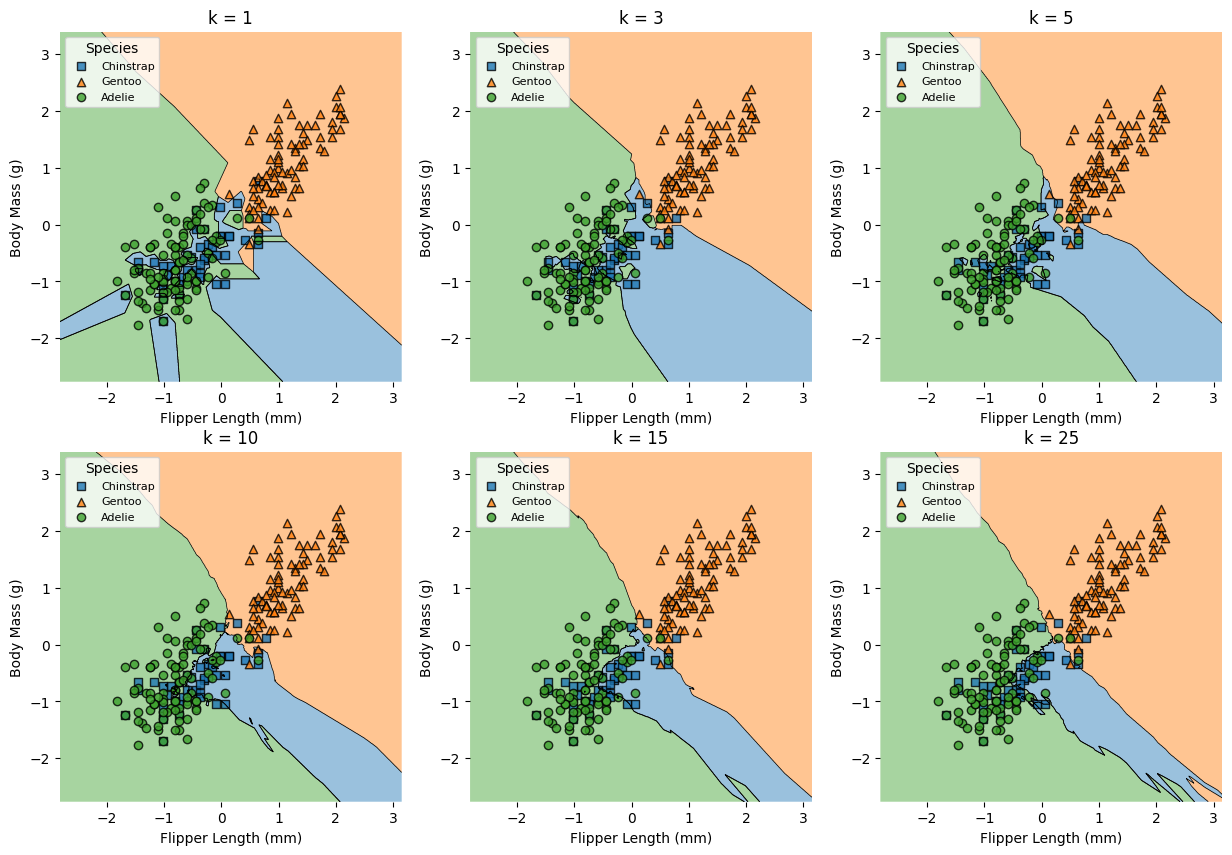

In [ ]:
fig, axes = plt.subplots(2, 3, figsize = (15, 10))
legend_elements = ['Chinstrap', 'Gentoo', 'Adelie']
for i, ax in enumerate(axes.flat):
    knn = KNeighborsClassifier(n_neighbors = k[i], metric='euclidean')
    knn.fit(scaled_train, y_train_np)
    plot_decision_regions(scaled_train, y_train_np, clf=knn, legend=0, ax=ax)
    ax.set_title(f'k = {k[i]}')
    ax.set_xlabel(f'Flipper Length (mm)')
    ax.set_ylabel(f'Body Mass (g)')
    ax.legend(loc = 'upper left', title='Species', fontsize=8, title_fontsize=10, labels=legend_elements)



**Задача 1.6 (0.5 балла)** Прокомментируйте результаты, полученные в задачах 1.3 и 1.5. Какое число соседей оптимально использовать для обучения классификатора? Поясните ваш выбор при помощи описания геометрии данных и получаемой решающей поверхности. Какие из результатов явно говорят о переобучении модели? Почему?

Анализируя доли правильных ответов при разных k ближайших соседей совершенно очевидно, что при k = 1 модель демонстрирует отличную точность на обучающей выборке(96%), но дает сбой на тестовой выборке(76%). Как таковое переобучение мы не наблюдаем при увеленичении k, оптимальным значением я предлагаю назвать k=15, поскольку оно имеет наивысшую точность по обеим выборкам.

### Задание 2. KNN своими руками. 2,5 балла


**Задача 2.1 (2 балла)** В данном задании мы попробуем реализовать алгоритм KNN своими руками, делать мы будем KNN именно для классификации.

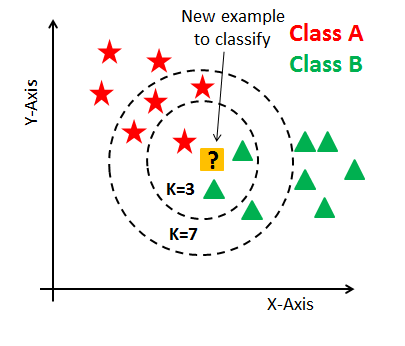

Рекомендации по реализации:
- Используйте `numpy` для представления данных в виде массивов, чтобы минимизировать преобразования.
- Избегайте циклов по всем объектам, по возможности используйте векторизированные операции.
- Обратите внимание на методы [np.linalg.norm()](https://numpy.org/doc/stable/reference/generated/numpy.linalg.norm.html) и [np.argsort()](https://numpy.org/doc/stable/reference/generated/numpy.argsort.html), а также на класс `collections.Counter`.
- Особый плюс, если учтёте обработку возможных ошибок.

In [ ]:

from scipy.spatial import distance
import numpy as np
from collections import Counter

class KNN:
    def __init__(self, k:int):
        self.k = k

    def fit(self, X, y):
        self.X_train = np.array(X)
        self.y_train = np.array(y)

    def predict(self, X):
        X_test = np.array(X)
        prediction = []
        for line_test in X_test:
            distant = np.linalg.norm(self.X_train - line_test, axis = 1)
            indexes_distances = np.argsort(distant)
            k_indexes = indexes_distances[:self.k]
            pre_res = self.y_train[k_indexes]
            res = Counter(pre_res)
            most_common = res.most_common(1)
            prediction.append(most_common[0][0])
        return np.array(prediction)

In [ ]:
# Не меняйте файл!
def test_knn(KNN):
  knn = KNN(k=1)
  X_train =  np.array([[1, 1], [2, 2]])
  y_train =  np.array([0, 1])
  X_test =  np.array([[1.5, 1.5]])
  knn.fit(X_train, y_train)
  assert knn.predict(X_test) == [0]

  knn = KNN(k=3)
  X_train = np.array([[1, 1], [2, 2], [3, 3], [4, 4], [5, 5], [6, 6], [7, 7], [8, 8], [9, 9], [10, 10]])
  y_train = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
  X_test = np.array([[9.5, 9.5]])
  knn.fit(X_train, y_train)
  assert knn.predict(X_test) == [1]

  knn = KNN(k=3)
  X_train = np.array([[1, 1], [2, 2], [3, 3], [4, 4], [5, 5], [6, 6], [7, 7], [8, 8], [9, 9], [10, 10]])
  y_train = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
  X_test = np.array([[5.5, 5.5]])
  knn.fit(X_train, y_train)
  assert knn.predict(X_test) == [1]

  knn = KNN(k=3)
  X_train = np.array([[1, 1], [2, 2], [3, 3], [4, 4], [5, 5], [6, 6], [7, 7], [8, 8], [9, 9], [10, 10]])
  y_train = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
  X_test = np.array([[15, 15]])
  knn.fit(X_train, y_train)
  assert knn.predict(X_test) == [1]

  knn = KNN(k=3)
  X_train = np.array([[1, 1], [2, 2], [3, 3], [4, 4], [5, 5], [6, 6], [7, 7], [8, 8], [9, 9], [10, 10]])
  y_train = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
  X_test = np.array([[5, 5], [2, 2]])
  knn.fit(X_train, y_train)
  assert all(knn.predict(X_test) == [1, 0])

In [ ]:
# Если тесты эти пройдены, то все верно!
test_knn(KNN)

**Задача 2.2 (0.5 балла)** Протестируйте ваш алгоритм на данных о пингвинах. Выведите лучший получившийся результат на тестовой выборке.

In [ ]:
k = [1, 3, 5, 10, 15, 25]
for i in range(len(k)):
     knn = KNN(k=k[i])
     knn.fit(X_train, y_train)
     prediction = knn.predict(X_train)
     prediction_test = knn.predict(X_test)
     train_acc = np.round(accuracy_score(y_train, prediction), 3)*100
     test_acc = np.round(accuracy_score(y_test, prediction_test), 4)*100
     print(f'Для k соседей ={k[i]} точность на обучающей выборке = {train_acc}%, на тестовой = {test_acc}%')


Для k соседей =1 точность на обучающей выборке = 100.0%, на тестовой = 71.43%
Для k соседей =3 точность на обучающей выборке = 87.2%, на тестовой = 71.43%
Для k соседей =5 точность на обучающей выборке = 83.2%, на тестовой = 68.37%
Для k соседей =10 точность на обучающей выборке = 79.2%, на тестовой = 68.37%
Для k соседей =15 точность на обучающей выборке = 75.2%, на тестовой = 68.37%
Для k соседей =25 точность на обучающей выборке = 76.1%, на тестовой = 69.39%


### Задание 3: Линейная регрессия.

В этом задании мы рассмотрим различные аспекты построения линейной модели. Мы будем работать с одним из классических наборов данных в статистике, содержащим информацию о бриллиантах. Описание можно посмотреть [здесь](https://www.kaggle.com/shivam2503/diamonds).

In [ ]:
data = pd.read_csv('diamonds.csv')
data.head(5)


,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


Мы будем решать задачу предсказания цены бриллианта `price` в зависимости от его характеристик.

**Задача 3.1 (0.2 балла)** Есть ли в наборе данных пропущенные значения? Если да, удалите их.
Есть ли в наборе данных бессмысленные столбцы (признаки, не несущие дополнительной информации)? Если да, то удалите их.

In [ ]:
print(f'train \n Количество пропусков: {data.isna().sum().sum()} \n Количество дублей: {data.duplicated().sum()} \n')
data = data.drop('Unnamed: 0', axis=1)

train 
 Количество пропусков: 0 
 Количество дублей: 0 



**Задача 3.2 (0.2 балла)** Линейная регрессия основана на предположении о линейной связи между признаками и целевой переменной, а потому перед выбором переменных для включения в модель имеет смысл проверить, насколько эта связь выполняется. Для следующих пунктов нам также потребуются выборочные корреляции между признаками. Постройте матрицу корреляций между всеми вещественными признаками и целевой переменной (то есть в этой матрице будет $k+1$ строка, где $k$ – количество вещественных признаков).

Какие вещественные признаки имеют наибольшую корреляцию с целевой переменной?

In [ ]:
corr_matr = data.select_dtypes(include=[np.number]).corr()
corr_matr

,carat,depth,table,price,x,y,z
carat,1.000000,0.028224,0.181618,0.921591,0.975094,0.951722,0.953387
depth,0.028224,1.000000,-0.295779,-0.010647,-0.025289,-0.029341,0.094924
table,0.181618,-0.295779,1.000000,0.127134,0.195344,0.183760,0.150929
price,0.921591,-0.010647,0.127134,1.000000,0.884435,0.865421,0.861249
x,0.975094,-0.025289,0.195344,0.884435,1.000000,0.974701,0.970772
y,0.951722,-0.029341,0.183760,0.865421,0.974701,1.000000,0.952006
z,0.953387,0.094924,0.150929,0.861249,0.970772,0.952006,1.000000


carat больше всего коррелирует с price, а x y z скорее всего образуют carat, поэтому также коррелируют с price.

**Задача 3.3 (0.2 балла)** Так как линейная модель складывает значения признаков с некоторыми весами, нам нужно аккуратно обработать категориальные признаки. Закодируйте категориальные признаки методом OneHot-кодирования (`pd.get_dummies()` или `OneHotEncoder` из `sklearn`).

In [ ]:
data_categorized = pd.get_dummies(data, columns=['cut', 'color', 'clarity'], dtype=int)
data_categorized

,carat,depth,table,price,x,y,z,cut_Fair,cut_Good,cut_Ideal,...,color_I,color_J,clarity_I1,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
0,0.23,61.5,55.0,326,3.95,3.98,2.43,0,0,1,...,0,0,0,0,0,1,0,0,0,0
1,0.21,59.8,61.0,326,3.89,3.84,2.31,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2,0.23,56.9,65.0,327,4.05,4.07,2.31,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0.29,62.4,58.0,334,4.20,4.23,2.63,0,0,0,...,1,0,0,0,0,0,0,1,0,0
4,0.31,63.3,58.0,335,4.34,4.35,2.75,0,1,0,...,0,1,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53935,0.72,60.8,57.0,2757,5.75,5.76,3.50,0,0,1,...,0,0,0,0,1,0,0,0,0,0
53936,0.72,63.1,55.0,2757,5.69,5.75,3.61,0,1,0,...,0,0,0,0,1,0,0,0,0,0
53937,0.70,62.8,60.0,2757,5.66,5.68,3.56,0,0,0,...,0,0,0,0,1,0,0,0,0,0
53938,0.86,61.0,58.0,2757,6.15,6.12,3.74,0,0,0,...,0,0,0,0,0,1,0,0,0,0


**Задача 3.4 (0.2 балла)** Разделите выборку на тренировочную и тестовую. Долю тестовой выборки укажите равной 0.3.

In [ ]:
Y = data_categorized['price']
data_categorized = data_categorized.drop(['price'], axis = 1)
X = data_categorized
Y

,price
0,326
1,326
2,327
3,334
4,335
...,...
53935,2757
53936,2757
53937,2757
53938,2757


In [ ]:
np.random.seed(52)
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size = 0.3)

**Задача 3.5 (0.3 балла)** Зачастую при использовании линейных моделей вещественные признаки масштабируются. При этом оценки коэффициентов теряют прямую статистическую интерпретацию ("при увеличении $X_1$ на 1, $y$ увеличивается на $w_1$"), но приобретают свойства, полезные в задачах машинного обучения. В этой задаче стандартизируйте вещественные признаки в тренировочной и тестовой выборках с помощью `StandardScaler`.

Объясните, как это повлияет на интерпретацию коэффициентов линейной регрессии.

In [ ]:
scaler = StandardScaler()
scaled_train = scaler.fit_transform(X_train)
scaled_test = scaler.transform(X_test)

После стандартизации признаков они приводятся (грубо говоря) к общему знаменателю, и мы можем наглядно увидеть какие признаки сильнее влияют на таргет

**Задача 3.6 (0.2 балла)** Оцените линейную регрессию на тренировочной выборке. Выведите среднеквадратичную ошибку на тренировочной и тестовой выборках.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Lasso, Ridge
from sklearn.linear_model import LassoCV
model = LinearRegression()
model.fit(scaled_train, y_train)

y_train_pred = model.predict(scaled_train)
y_test_pred = model.predict(scaled_test)

mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)

print(f"MSE на тренировочной: {mse_train:.2f}")
print(f"MSE на тестовой: {mse_test:.2f}")

MSE на тренировочной: 1283859.07
MSE на тестовой: 1261612.96


**Задача 3.7 (0.3 балла)** Изучите [документацию](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) модуля `LinearRegression` и выведите полученные оценки коэффициентов. Назовите вещественные переменные, оценки коэффициентов которых по модулю на порядок превышают оценки прочих вещественных переменных.

In [ ]:
coefs = model.coef_
w_zero = model.intercept_
rounded_coefs = np.round(coefs, 2)
formatted = [f"{x}" for x in rounded_coefs]
print(formatted)
print(f'Свободный член w0 = {np.round(w_zero, 2)}')

['5279.55', '-96.28', '-65.81', '-1075.77', '0.8', '-28.77', '-129.44', '-37.2', '51.34', '17.06', '0.38', '206.25', '160.73', '132.36', '57.39', '-123.11', '-248.68', '-382.55', '-475.97', '231.22', '-147.28', '-493.72', '208.6', '110.11', '245.53', '282.44']
Свободный член w0 = 3929.02


Очевидным образом Carat по модулю имеет наибольший вес, в таблице корреляций мы уже увидели, что он сильнее всего влияет на таргет, и коррелирует ещё с другими параметрами, что ещё усиливает его влияние.

**Задача 3.8 (0.5 балла)** Как можно заметить из анализа корреляционной матрицы в задаче 3.3, между некоторыми признаками имеется сильная корреляция, что может быть индикатором проблемы *мультиколлинеарности*. Различия в порядке коэффициентов, выявленные в предыдущей задаче также намекают на её присутствие. Как известно, для решения этой проблемы можно либо исключить некоторые признаки из модели, либо использовать регуляризацию. Мы воспользуемся вторым вариантом.

Вспомним, что смысл регуляризации заключается в том, чтобы изменить функцию потерь так, чтобы устранить проблемы, появляющиеся из-за мультиколлинеарности. При L1-регуляризации предлагается минимизировать следующую функцию потерь:

$$
\|y - X\hat{w}\|^2 + \alpha\sum_{i=1}^k|w_i|
$$

Такая модель называется Lasso-регрессией.

При L2-регуляризации предлагается минимизировать следующую функцию потерь:

$$
\|y - X\hat{w}\|^2 + \alpha\|w\|^2
$$

Такая модель называется Ridge-регрессией.

Обучите Lasso-регрессию и Ridge-регрессию, установив гиперпараметр регуляризации равным 10. Для этого используйте модули `Lasso` и `Ridge` из `sklearn`. Сильно ли уменьшились веса? Сделайте вывод о том, насколько сильно проблема мультиколлинеарности проявлялась в изначальной регрессии.

In [ ]:
alpha = 10
ridge = Ridge(alpha=alpha, random_state = 52)
ridge.fit(scaled_train, y_train)
lasso = Lasso(alpha=alpha, random_state = 52)
lasso.fit(scaled_train, y_train)

coefs_ridge = ridge.coef_
coefs_lasso = lasso.coef_

#Округляем коэффициенты
rounded_coefs_ridge = np.round(coefs_ridge, 2)
rounded_coefs_lasso = np.round(coefs_lasso, 2)
formatted_coefs_ridge = [f'{x}' for x in rounded_coefs_ridge]
formatted_coefs_lasso = [f'{x}' for x in rounded_coefs_lasso]

#Вывод коэффициентов
print(formatted_coefs_ridge)
print(formatted_coefs_lasso)

['5242.78', '-93.71', '-65.52', '-1033.54', '-1.58', '-32.93', '-129.61', '-37.3', '51.34', '17.07', '0.51', '205.99', '160.52', '131.92', '57.12', '-122.84', '-248.05', '-381.84', '-475.44', '231.57', '-147.82', '-493.6', '208.43', '109.93', '246.02', '282.71']
['4816.01', '-62.96', '-52.12', '-619.48', '-0.0', '-41.5', '-130.51', '-38.46', '41.49', '0.0', '-0.0', '142.24', '90.57', '61.71', '-0.0', '-165.56', '-277.13', '-398.65', '-493.39', '178.26', '-260.65', '-583.98', '101.61', '-0.0', '175.28', '199.09']


Поскольку при α=10 веса Ridge и Lasso практически не отличаются от весов
обычной регрессии, можно сделать вывод,
что проблема мультиколлинеарности в исходных данных практически отсутствовала.
Коэффициенты исходной модели были стабильны и не нуждались в регуляризации.

In [ ]:
#Строим предикты для Ridge
ridge_y_train_pred = ridge.predict(scaled_train)
ridge_y_test_pred = ridge.predict(scaled_test)

#Строим предикты для lasso
lasso_y_train_pred = lasso.predict(scaled_train)
lasso_y_test_pred = lasso.predict(scaled_test)

#считаем MSE для lasso и Ridge на тестовой и тренеровочной выборках
mse_train_ridge = mean_squared_error(y_train, ridge_y_train_pred)
mse_train_lasso = mean_squared_error(y_train, lasso_y_train_pred)
mse_test_ridge = mean_squared_error(y_test, ridge_y_test_pred)
mse_test_lasso = mean_squared_error(y_test, lasso_y_test_pred)

**Задача 3.9 (0.5 балла)** Как обсуждалось на семинарах, Lasso-регрессию можно использовать для отбора наиболее информативных признаков. Для следующих значений параметра регуляриазции $\alpha$: 0.1, 1, 10, 100, 200 –  обучите Lasso- и Ridge-регрессии и постройте график измненения евклидовой нормы весов (`np.linalg.norm()` от вектора оценок коэффициентов) в зависимости от параметра $\alpha$. Как известно, норма является численной характеристикой величины вектора, а потому по норме можно судить о том, насколько большие элементы содержит вектор оценок коэффициентов.

Какой метод сильнее снижает норму коэффициентов? Поясните, почему Lasso-регрессию часто используют для отбора признаков.

(3500.0, 5500.0)

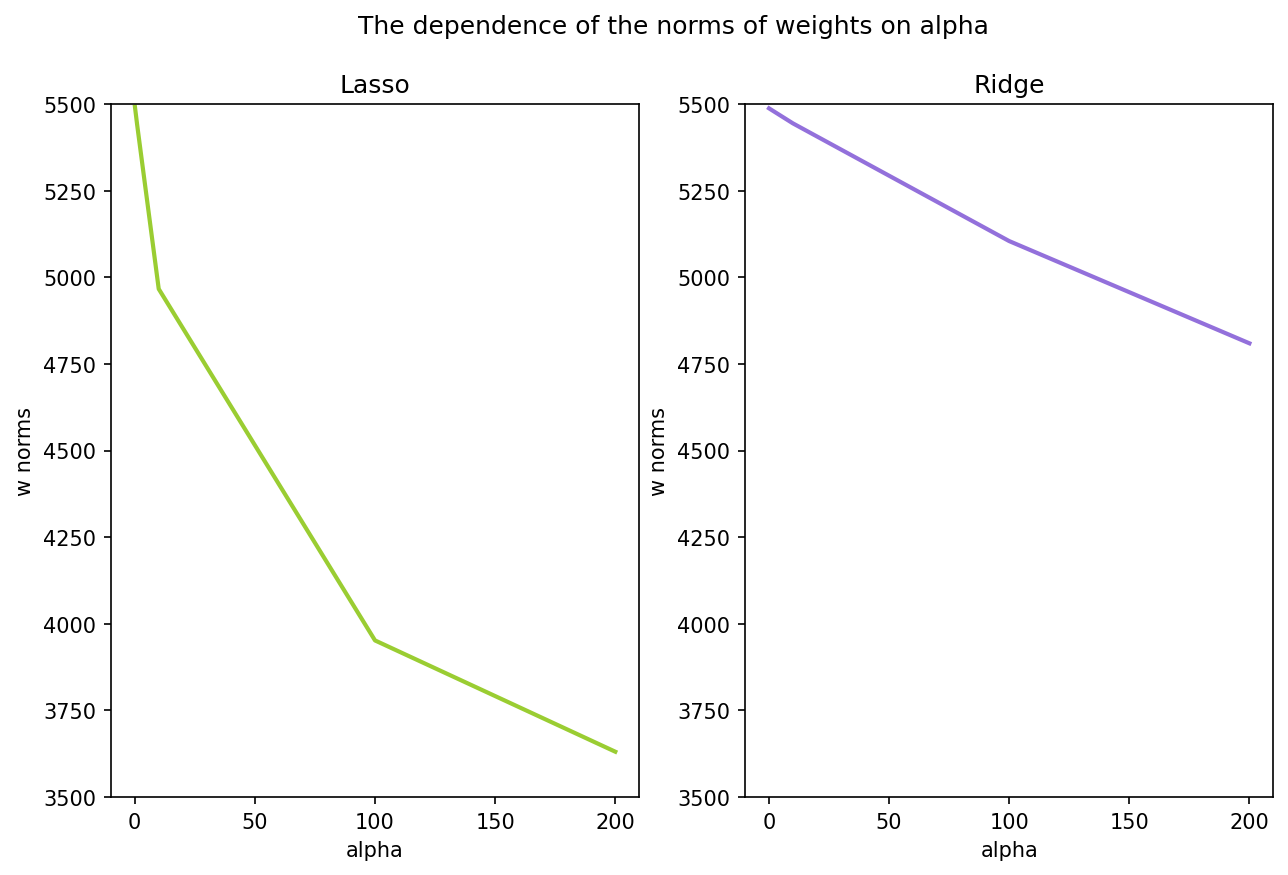

In [ ]:
alphas = [0.1, 1, 10, 100, 200]
lst_norms_lasso = []
lst_norms_ridge = []
for alpha in alphas:
    ridge = Ridge(alpha=alpha, random_state = 52)
    ridge.fit(scaled_train, y_train)
    lasso = Lasso(alpha=alpha, random_state = 52)
    lasso.fit(scaled_train, y_train)
    coefs_ridge = ridge.coef_
    coefs_lasso = lasso.coef_

    #Округляем коэффициенты
    rounded_coefs_ridge = np.round(coefs_ridge, 2)
    rounded_coefs_lasso = np.round(coefs_lasso, 2)
    formatted_coefs_ridge = [f'{x}' for x in rounded_coefs_ridge]
    formatted_coefs_lasso = [f'{x}' for x in rounded_coefs_lasso]
    norma_vesov_lasso = np.linalg.norm(formatted_coefs_lasso, ord=2)
    norma_vesov_ridge = np.linalg.norm(formatted_coefs_ridge, ord=2)
    lst_norms_lasso.append(norma_vesov_lasso)
    lst_norms_ridge.append(norma_vesov_ridge)
plt.figure(figsize=(10, 6), dpi=150)
plt.suptitle('The dependence of the norms of weights on alpha')
plt.subplot(1, 2, 1)
plt.plot(alphas, lst_norms_lasso, color='yellowgreen', linewidth=2)
plt.title('Lasso')
plt.xlabel('alpha')
plt.ylabel('w norms')
plt.ylim(3500, 5500)
plt.subplot(1, 2, 2)
plt.plot(alphas, lst_norms_ridge, color='mediumpurple', linewidth=2)
plt.title('Ridge')
plt.xlabel('alpha')
plt.ylabel('w norms')
plt.ylim(3500, 5500)


Сильнее снижает норму коэффициентов метод Lasso, поскольку он зануляет коэффициенты. По этой причине часто используют Lasso регрессию, чтобы отбросить ненужные признаки.

**Задача 3.10 (0.5 балла)**
В зависимости от значения параметра $\alpha$ в Lasso-регрессии зануляются разные оценки коэффициентов. Оптимальное значение $\alpha$ можно подобрать, например, при помощи кросс-валидации по тренировочной выборке.

Для проведения кросс-валидации можно использовать модуль `LassoCV`. Этот модуль принимает список значений $\alpha$ (параметр `alphas`) и при обучении проводит кросс-валидацию для каждого значения из этого списка, сохраняя MSE на каждом участке кросс-валидации (количество участков – параметр `cv`) в матрицу ошибок (то есть итоговая матрица будет иметь размер `len(alphas)` $\times$ `cv`). После обучения модели матрицу ошибок можно получить, обратившись к атрибуту `.mse_path_`.

Заметим, что модель может использовать $\alpha$ не в том порядке, в котором вы подаёте их в функцию: для определения порядка используйте атрибут `.alphas_` Установите количество участков для кросс-валидации (параметр `cv`) равным 5.

Усредните ошибки для каждого значения $\alpha$ (то есть по строкам матрицы ошибок) и выберите то значение, которое даёт наибольшее качество.

In [ ]:
alphas = [0.1, 1, 10, 100, 200]
lasso_cv = LassoCV(alphas=alphas, cv=5, random_state=52)
lasso_cv.fit(scaled_train, y_train)
mistakes_matrix = lasso_cv.mse_path_
mean_MSE = np.mean(mistakes_matrix, axis=1)
min_mmse_ind = np.argmin(mean_MSE)
best_alpha = lasso_cv.alphas_[min_mmse_ind]
best_MSE = mean_MSE[min_mmse_ind]
print(f'лучшее альфа = {best_alpha}')
print(f'MSE при этом альфа = {np.round(best_MSE, 2)}')

лучше альфа = 1.0
MSE при этом альфа = 1288418.07


**Задача 3.11 (0.5 балла)** Обучите итоговую Lasso-регрессию с выбранным параметром $\alpha$ на тренировочной выборке. Выведите полученные коэффициенты и прокомментируйте, какие признаки оказались неинформативными, а какие – наиболее информативными. Приведите возможное смысловое объяснение этого результата.

In [ ]:
data_categorized.head(10)

,carat,depth,table,x,y,z,cut_Fair,cut_Good,cut_Ideal,cut_Premium,...,color_I,color_J,clarity_I1,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
0,0.23,61.5,55.0,3.95,3.98,2.43,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
1,0.21,59.8,61.0,3.89,3.84,2.31,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
2,0.23,56.9,65.0,4.05,4.07,2.31,0,1,0,0,...,0,0,0,0,0,0,1,0,0,0
3,0.29,62.4,58.0,4.20,4.23,2.63,0,0,0,1,...,1,0,0,0,0,0,0,1,0,0
4,0.31,63.3,58.0,4.34,4.35,2.75,0,1,0,0,...,0,1,0,0,0,1,0,0,0,0
5,0.24,62.8,57.0,3.94,3.96,2.48,0,0,0,0,...,0,1,0,0,0,0,0,0,0,1
6,0.24,62.3,57.0,3.95,3.98,2.47,0,0,0,0,...,1,0,0,0,0,0,0,0,1,0
7,0.26,61.9,55.0,4.07,4.11,2.53,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
8,0.22,65.1,61.0,3.87,3.78,2.49,1,0,0,0,...,0,0,0,0,0,0,0,1,0,0
9,0.23,59.4,61.0,4.00,4.05,2.39,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [ ]:
alpha = 1
lasso = Lasso(alpha=alpha, random_state = 52)
lasso.fit(scaled_train, y_train)
coefs_lasso = lasso.coef_
rounded_coefs_lasso = np.round(coefs_lasso, 2)
formatted_coefs_lasso = [f'{x}' for x in rounded_coefs_lasso]
print(formatted_coefs_lasso)

['5233.71', '-92.96', '-64.44', '-1029.87', '-0.0', '-30.01', '-135.54', '-47.37', '33.2', '0.0', '-14.22', '158.11', '105.32', '77.37', '-0.0', '-172.83', '-289.5', '-412.15', '-505.53', '184.17', '-259.65', '-592.01', '113.42', '-0.0', '179.72', '205.01']


In [ ]:
feature_names = data_categorized.columns  # или data_categorized.columns после get_dummies

coef_df = pd.DataFrame({
    'Признак': feature_names,
    'Коэффициент': rounded_coefs_lasso
})
coef_df['|Коэф|'] = coef_df['Коэффициент'].abs()
coef_df_sorted = coef_df.sort_values('|Коэф|', ascending=False)

print("ТОП-10 САМЫХ ВЛИЯТЕЛЬНЫХ ПРИЗНАКОВ:")
print(coef_df_sorted.head(10).to_string(index=False))

print("\nПРИЗНАКИ С НУЛЕВЫМИ КОЭФФИЦИЕНТАМИ (неинформативные):")
zero_coefs = coef_df[coef_df['Коэффициент'] == 0]
print(zero_coefs[['Признак', 'Коэффициент']].to_string(index=False))

ТОП-10 САМЫХ ВЛИЯТЕЛЬНЫХ ПРИЗНАКОВ:
     Признак  Коэффициент  |Коэф|
       carat      5233.71 5233.71
           x     -1029.87 1029.87
 clarity_SI2      -592.01  592.01
  clarity_I1      -505.53  505.53
     color_J      -412.15  412.15
     color_I      -289.50  289.50
 clarity_SI1      -259.65  259.65
clarity_VVS2       205.01  205.01
  clarity_IF       184.17  184.17
clarity_VVS1       179.72  179.72

ПРИЗНАКИ С НУЛЕВЫМИ КОЭФФИЦИЕНТАМИ (неинформативные):
    Признак  Коэффициент
          y         -0.0
cut_Premium          0.0
    color_G         -0.0
clarity_VS2         -0.0


Карат оказался самым влиятельным признаком. Это разумно, чем больше вес, тем выше цена. ТАкже мы наблюдаем отрицательное влияние длины(х). Возможно чем блиннее бриллиант, тем он дешевле(менее мобилный для использования, менее элегантный)

**Задача 3.12 (0.4 балла)** Сделайте предсказания обученной Lasso-регрессии на тестовой выборке и сравните среднеквадратичную ошибку с ошибкой обычной линейной регрессии из задачи 3.7. Какую модель лучше использовать для предсказаний? Приведите возможное объяснение, почему одна модель оказалась лучше другой.

In [ ]:
lasso_y_test_pred = lasso.predict(scaled_test)
mse_test_lasso = mean_squared_error(y_test, lasso_y_test_pred)
print(f"MSE на тестовой: {mse_test_lasso:.2f}")

MSE на тестовой: 1262491.31


В обеих моделях отличие составило менее 0.1%, поэтому нельзя однозначно сказать какая модель лучше.